# Diamonds

## Постановка задачи
Задача заключается в **прогнозировании стоимости** бриллианта на основе его физических параметров и качественных характеристик

**Названия столбцов с пояснением:**
 - **Unnamed: 0** технический столбец
 - **price:**	 Цена в долларах США (\$326--\$18,823). **ТАРГЕТ**
 - **carat:**	 Вес бриллианта в каратах (0.2--5.01)
 - **cut:**	 Качество огранки (Fair, Good, Very Good, Premium, Ideal)
 - **color:**	 Цвет бриллианта, от J (худший) до D (лучший)
 - **clarity:**	 Чистота бриллианта - мера прозрачности камня (I1 (худшая), SI2, SI1, VS2, VS1, VVS2, VVS1, IF (лучшая))
 - **x:**	 Длина в мм (0--10.74)
 - **y:**	 Ширина в мм (0--58.9)
 - **z:**	 Глубина в мм (0--31.8)
 - **depth:**	 Общая глубина в процентах = z / mean(x, y) = 2 * z / (x + y) (43--79)
 - **table:**	 Ширина верхней части бриллианта относительно самой широкой точки (43--95)

## Импорт основных библиотек

In [1]:
# Необходимо для корректной работы внешних .py файлов
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from lightgbm import LGBMRegressor
import seaborn as sns
from helper import *
from plots import *
import random

In [3]:
# фиксируем состояние генератора псевдослучайных чисел. Это необходимо, чтобы результаты модели не менялись с каждым новым запуском 
SEED = 42 # можно указать любое число
np.random.seed(SEED)
random.seed(SEED)

##  1. Изучение структуры данных

In [4]:
# Загружаем датасет в память
df = pd.read_csv("diamonds.csv")
df.head(5)

,Unnamed: 0,carat,cut,color,clarity,depth,table,price,x,y,z
0,1,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,2,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,3,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,4,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,5,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [5]:
# Смотрим на детали
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  53940 non-null  int64  
 1   carat       53940 non-null  float64
 2   cut         53940 non-null  object 
 3   color       53940 non-null  object 
 4   clarity     53940 non-null  object 
 5   depth       53940 non-null  float64
 6   table       53940 non-null  float64
 7   price       53940 non-null  int64  
 8   x           53940 non-null  float64
 9   y           53940 non-null  float64
 10  z           53940 non-null  float64
dtypes: float64(6), int64(2), object(3)
memory usage: 4.5+ MB


In [6]:
# Смотрим на статистики по числовым переменным (категориальные сюда не входят)
df.describe()

,Unnamed: 0,carat,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,26970.500000,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,15571.281097,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,1.000000,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,13485.750000,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,26970.500000,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,40455.250000,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,53940.000000,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


In [7]:
# удаляем столбец Unnamed: 0, поскольку он не несет пользы в дальнейшем исследовании
df = df.drop(columns=['Unnamed: 0'])

## 2. Проверка на корректность и качество данных

### 2.1 Проверка на дубликаты

In [8]:
# Подсчет числа дублированных строк
df.duplicated().sum() 

np.int64(146)

Дубликатов в датасете нет

### 2.2 Пропущенные значения

In [9]:
# выводим число пропущенных значений по каждому столбцу
df.isnull().sum()

carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64

Пропусков нет

### 2.3 Корректность по столбцам

In [10]:
# Убедимся, нет отрицательных значений carat        
len(df[df['carat'] < 0])

0

In [11]:
# Убедимся, в корректности значений
df['cut'].value_counts()

cut
Ideal        21551
Premium      13791
Very Good    12082
Good          4906
Fair          1610
Name: count, dtype: int64

In [12]:
# Убедимся, в корректности значений
df['color'].value_counts()

color
G    11292
E     9797
F     9542
H     8304
D     6775
I     5422
J     2808
Name: count, dtype: int64

In [13]:
# Убедимся, в корректности значений
df['clarity'].value_counts()

clarity
SI1     13065
VS2     12258
SI2      9194
VS1      8171
VVS2     5066
VVS1     3655
IF       1790
I1        741
Name: count, dtype: int64

In [14]:
# Убедимся, нет отрицательных значений depth (Общая глубина в процентах)      
len(df[df['depth'] < 0])

0

In [15]:
# Убедимся, нет отрицательных значений table (Ширина верхней части алмаза)
len(df[df['table'] < 0])

0

In [16]:
# Убедимся, нет отрицательных значений price        
len(df[df['price'] < 0])

0

In [17]:
# Убедимся, нет отрицательных значений у длины, ширины и грубины  
print(len(df[df['x'] < 0]))
print(len(df[df['y'] < 0]))
print(len(df[df['z'] < 0]))


0
0
0


## 3. Детальное изучение признаков (и таргета)

Примечание: по хорошему стоит также учесть пропущенные значения при построении графиков, предварительно заменив их на константу, чтобы видеть более общую картину, но поскольку в этом датасете максимальная их доля в столбце составляет 8%, мы пропустим этот шаг

### 3.1 Числовые переменные

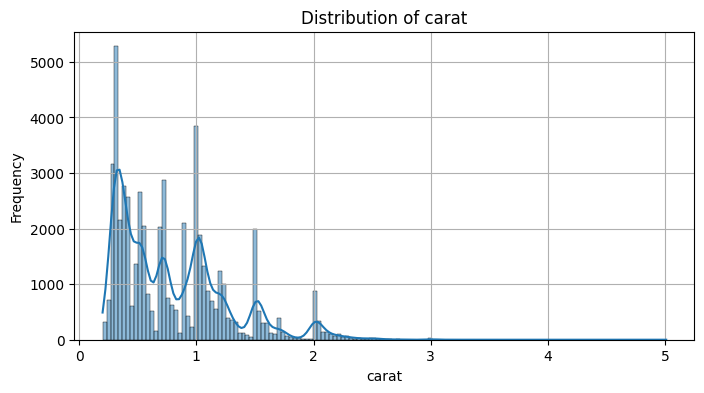

In [18]:
# Строим гистограмму распределения  carat
plot_hist_numeric(df, 'carat')

Большая часть данных расположена в диапазоне от 0,5 до 2,5, смещены в левую сторону, ближе к нулю, что логично, так как малых блиллиантов много, а большие встречаются редко

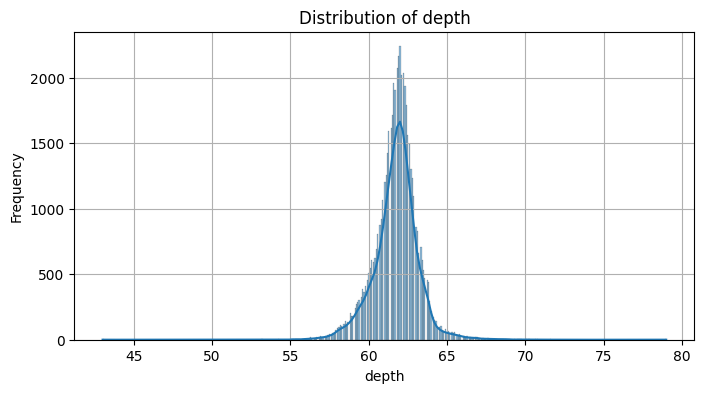

In [19]:
# Строим гистограмму распределения depth
plot_hist_numeric(df, 'depth')

Видим, что распределение нормальное

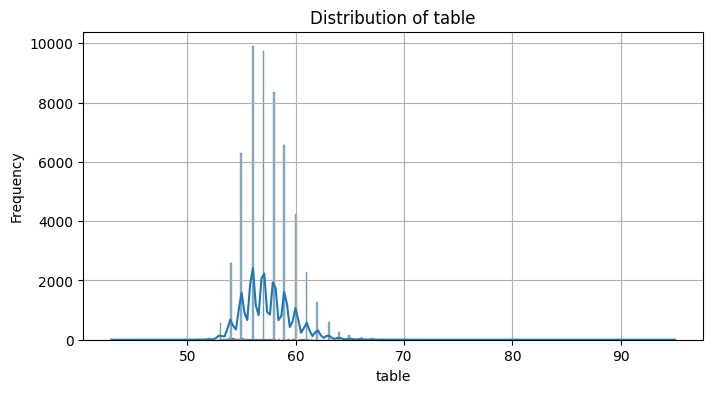

In [20]:
# Строим гистограмму распределения table       
plot_hist_numeric(df, 'table')

Видим, что основная масса значений находится в диапазоне 52 - 65, распределение похоже на нормальное

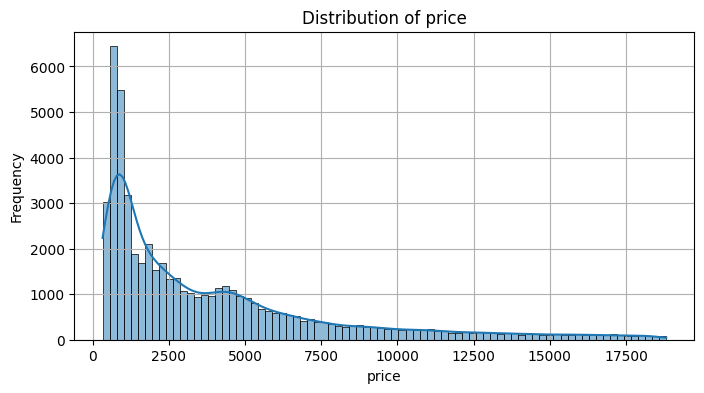

In [21]:
# Строим гистограмму распределения price       
plot_hist_numeric(df, 'price')

График походит на график с carat, большая часть данных находится с лева от центра

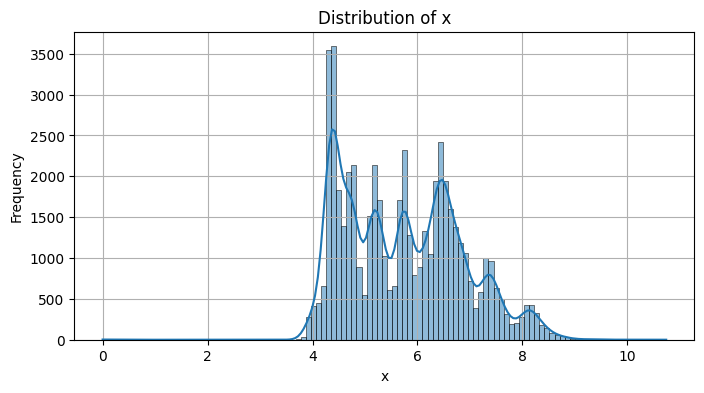

In [22]:
# Строим гистограмму распределения x       
plot_hist_numeric(df, 'x')

Видим, что основная масса значений находится в диапазоне 4 - 9

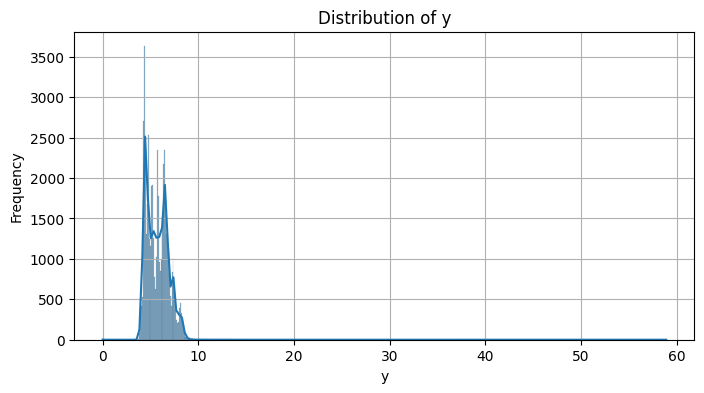

In [23]:
# Строим гистограмму распределения y     
plot_hist_numeric(df, 'y')

Видим, что основная масса значений находится в диапазоне до 10

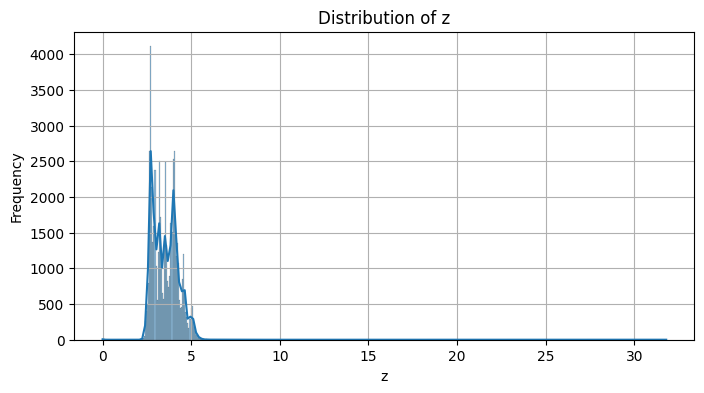

In [24]:
# Строим гистограмму распределения z       
plot_hist_numeric(df, 'z')

Видим, что основная масса значений находится в диапазоне 2 - 6

### 3.2 Категориальные переменные

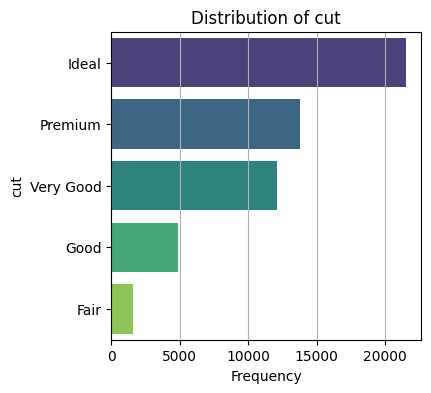

In [25]:
# Строим гистограмму распределения cut
plot_hist_categorical(df, 'cut')

Большинство с качеством огранки Ideal

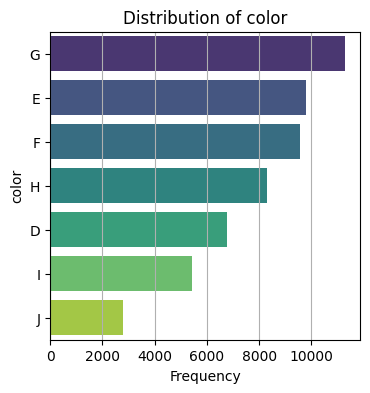

In [26]:
# Строим гистограмму распределения color
plot_hist_categorical(df, 'color')

От худшего к лучшему:
J → I → H → G → F → E → D

Большинство среднего качества

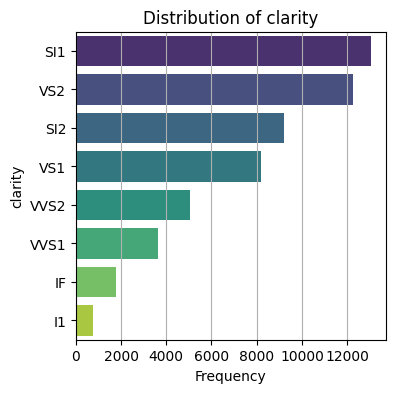

In [27]:
# Строим гистограмму распределения clarity  (чистота бриллианта)   
plot_hist_categorical(df, 'clarity')

От худшего к лучшему:
I1 → SI2 → SI1 → VS2 → VS1 → VVS2 → VVS1 → IF

- I1  — включения (внутренние дефекты) видны невооруженным глазом
- SI2, SI1  — небольшие включения, видны под увеличением
- VS2, VS1 — очень небольшие включения
- VVS2, VVS1 — минимальные включения, трудно обнаружить даже под увеличением
- IF — безупречная чистота, нет внутренних дефектов

Чаще всего встречаются блилианты средней чистоты  
Лучшей и худшей меньше всего



## 4. Изучение взаимосвязей между признаками

### 4.1 Общая матрица корреляций

interval columns not set, guessing: ['carat', 'depth', 'table', 'price', 'x', 'y', 'z']


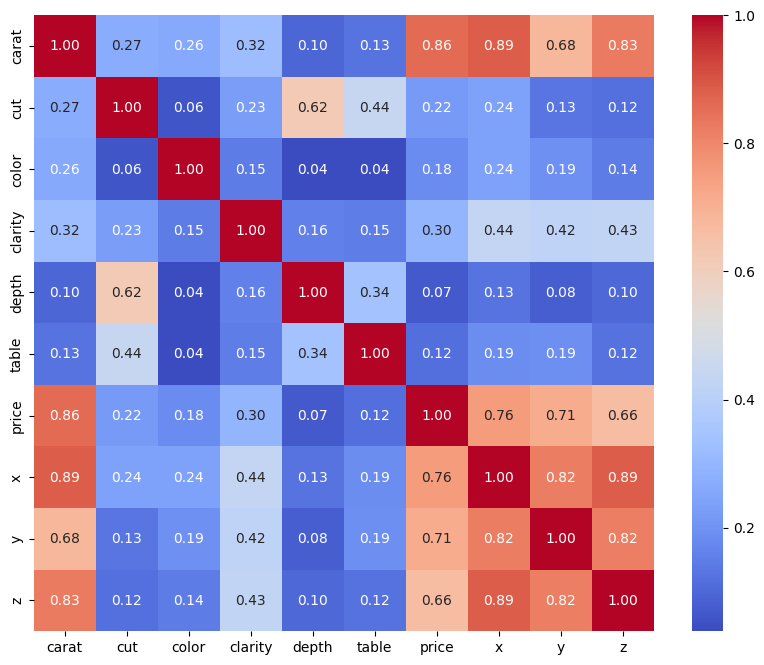

In [28]:
# поскольку в нашем датасете присутствуют категориальные признаки, используем корреляцию phik, которая способна с ними работать
plot_phik(df)

Больше всего коррелируют с целевой переменной:
- carat
- x
- y
- z

Ячейки с более высокими значениями корреляции:
- carat vs x
- carat vs y
- carat vs z
- x vs y
- x vs z
- y vs z
- cut vs depth

По сути это означает, что на цену больше всего влияет размер блиллианта  

## 5. Препроцессинг данных


### 5.1 Общие преобразования

In [29]:
df_preprocessed = df.copy()

In [ ]:
df_preprocessed.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53940 non-null  float64
 1   cut      53940 non-null  object 
 2   color    53940 non-null  object 
 3   clarity  53940 non-null  object 
 4   depth    53940 non-null  float64
 5   table    53940 non-null  float64
 6   price    53940 non-null  int64  
 7   x        53940 non-null  float64
 8   y        53940 non-null  float64
 9   z        53940 non-null  float64
dtypes: float64(6), int64(1), object(3)
memory usage: 4.1+ MB


### 5.2 Разбиение датасета 

In [31]:
# делим данные на признаки и таргет
X, y = divide_data(df_preprocessed, 'price')

In [32]:
# Разбиваем данные на train и test с соотношением 80 на 20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=SEED, 
)

In [33]:
X_train

,carat,cut,color,clarity,depth,table,x,y,z
26546,2.01,Good,F,SI2,58.1,64.0,8.23,8.19,4.77
9159,1.01,Very Good,E,SI2,60.0,60.0,6.57,6.49,3.92
14131,1.10,Premium,H,VS2,62.5,58.0,6.59,6.54,4.10
15757,1.50,Good,E,SI2,61.5,65.0,7.21,7.17,4.42
24632,1.52,Very Good,G,VS1,62.1,57.0,7.27,7.32,4.53
...,...,...,...,...,...,...,...,...,...
11284,1.05,Very Good,I,VS2,62.4,59.0,6.48,6.51,4.05
44732,0.47,Ideal,D,VS1,61.0,55.0,5.03,5.01,3.06
38158,0.33,Very Good,F,IF,60.3,58.0,4.49,4.46,2.70
860,0.90,Premium,J,SI1,62.8,59.0,6.13,6.03,3.82


In [34]:
X_train_preprocessed = X_train.copy()

In [35]:
categorical_cols = ['cut', 'color', 'clarity']
numeric_cols = ['carat', 'depth', 'table', 'price', 'x', 'y', 'z']

### 5.1 Обработка пропущенных значений

In [36]:
X_train_preprocessed.isnull().sum()

carat      0
cut        0
color      0
clarity    0
depth      0
table      0
x          0
y          0
z          0
dtype: int64

### 5.2 Кодирование категориальных переменных

In [37]:
# Будем использовать порядковое кодирование. Для этого выпишем все категории для каждого столбца в порядке увеличения номера
category_orders = [
    ['Fair', 'Good', 'Very Good', 'Premium', 'Ideal'], # cut 
    ['J','I', 'H', 'G', 'F', 'E', 'D'], # color                          
    ['I1', 'SI2', 'SI1', 'VS2', 'VS1', 'VVS2', 'VVS1', 'IF'], # clarity     
]

encoder = OrdinalEncoder(categories=category_orders)
X_train_preprocessed[categorical_cols] = encoder.fit_transform(X_train_preprocessed[categorical_cols])

In [38]:
# посмотрим на результат работы кодировщика
X_train_preprocessed

,carat,cut,color,clarity,depth,table,x,y,z
26546,2.01,1.0,4.0,1.0,58.1,64.0,8.23,8.19,4.77
9159,1.01,2.0,5.0,1.0,60.0,60.0,6.57,6.49,3.92
14131,1.10,3.0,2.0,3.0,62.5,58.0,6.59,6.54,4.10
15757,1.50,1.0,5.0,1.0,61.5,65.0,7.21,7.17,4.42
24632,1.52,2.0,3.0,4.0,62.1,57.0,7.27,7.32,4.53
...,...,...,...,...,...,...,...,...,...
11284,1.05,2.0,1.0,3.0,62.4,59.0,6.48,6.51,4.05
44732,0.47,4.0,6.0,4.0,61.0,55.0,5.03,5.01,3.06
38158,0.33,2.0,4.0,7.0,60.3,58.0,4.49,4.46,2.70
860,0.90,3.0,0.0,2.0,62.8,59.0,6.13,6.03,3.82


### 5.3 Итоговый пайплайн для препроцессинга


In [ ]:
preprocessor = ColumnTransformer(
    [('encoder', OrdinalEncoder(categories=category_orders), categorical_cols)],
    remainder='passthrough', 
    verbose_feature_names_out=False
)
preprocessor.set_output(transform="pandas")

X_train_preprocessed = preprocessor.fit_transform(X_train)


In [40]:
# смотрим на результат работы пайплайна
X_train_preprocessed 

,cut,color,clarity,carat,depth,table,x,y,z
26546,1.0,4.0,1.0,2.01,58.1,64.0,8.23,8.19,4.77
9159,2.0,5.0,1.0,1.01,60.0,60.0,6.57,6.49,3.92
14131,3.0,2.0,3.0,1.10,62.5,58.0,6.59,6.54,4.10
15757,1.0,5.0,1.0,1.50,61.5,65.0,7.21,7.17,4.42
24632,2.0,3.0,4.0,1.52,62.1,57.0,7.27,7.32,4.53
...,...,...,...,...,...,...,...,...,...
11284,2.0,1.0,3.0,1.05,62.4,59.0,6.48,6.51,4.05
44732,4.0,6.0,4.0,0.47,61.0,55.0,5.03,5.01,3.06
38158,2.0,4.0,7.0,0.33,60.3,58.0,4.49,4.46,2.70
860,3.0,0.0,2.0,0.90,62.8,59.0,6.13,6.03,3.82


In [ ]:
X_train_preprocessed.info()

<class 'pandas.core.frame.DataFrame'>
Index: 43152 entries, 26546 to 15795
Data columns (total 9 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   cut      43152 non-null  float64
 1   color    43152 non-null  float64
 2   clarity  43152 non-null  float64
 3   carat    43152 non-null  float64
 4   depth    43152 non-null  float64
 5   table    43152 non-null  float64
 6   x        43152 non-null  float64
 7   y        43152 non-null  float64
 8   z        43152 non-null  float64
dtypes: float64(9)
memory usage: 3.3 MB


## 6. Построение базовой модели (baseline)

In [ ]:
# применяем уже обученный пайплайн к тестовой выборке. 
X_test_preprocessed = preprocessor.transform(X_test)

In [43]:
X_test_preprocessed

,cut,color,clarity,carat,depth,table,x,y,z
1388,4.0,3.0,6.0,0.24,62.1,56.0,3.97,4.00,2.47
50052,2.0,4.0,5.0,0.58,60.0,57.0,5.44,5.42,3.26
41645,4.0,5.0,5.0,0.40,62.1,55.0,4.76,4.74,2.95
42377,3.0,5.0,5.0,0.43,60.8,57.0,4.92,4.89,2.98
17244,4.0,5.0,1.0,1.55,62.3,55.0,7.44,7.37,4.61
...,...,...,...,...,...,...,...,...,...
44081,2.0,5.0,4.0,0.50,61.6,59.0,5.06,5.14,3.14
23713,2.0,4.0,5.0,0.25,61.6,57.0,4.05,4.07,2.50
31375,1.0,3.0,6.0,0.31,58.0,62.0,4.42,4.47,2.58
21772,4.0,4.0,4.0,1.23,62.5,54.0,6.85,6.82,4.27


In [44]:
X_test_preprocessed.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10788 entries, 1388 to 4998
Data columns (total 9 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   cut      10788 non-null  float64
 1   color    10788 non-null  float64
 2   clarity  10788 non-null  float64
 3   carat    10788 non-null  float64
 4   depth    10788 non-null  float64
 5   table    10788 non-null  float64
 6   x        10788 non-null  float64
 7   y        10788 non-null  float64
 8   z        10788 non-null  float64
dtypes: float64(9)
memory usage: 842.8 KB


In [45]:
X_test_preprocessed.isnull().sum()

cut        0
color      0
clarity    0
carat      0
depth      0
table      0
x          0
y          0
z          0
dtype: int64

In [46]:
feature_names = X_test_preprocessed.columns.to_list()

### 6.1 Dummy Regressor 

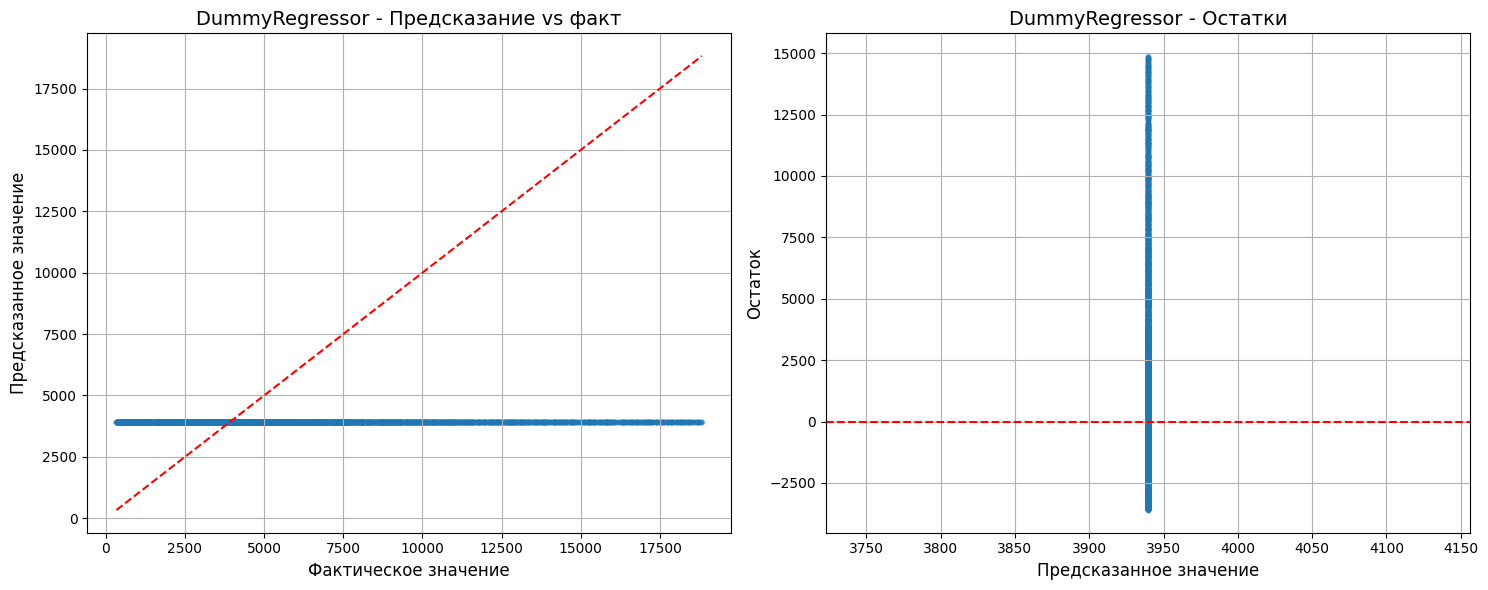


                 DUMMYREGRESSOR EVALUATION                  

MAIN METRICS:
 Metric     Value
    MAE 3020.5058
   RMSE 3987.2222
     R2   -0.0001
MAPE, %  190.1682



In [ ]:
dummy_regressor = DummyRegressor(strategy='mean')
dummy_regressor.fit(X_train_preprocessed, y_train)
y_pred = dummy_regressor.predict(X_test_preprocessed)

dummy_regressor_metrics = evaluate_regression(
    y_test=y_test, y_pred=y_pred, model_name="DummyRegressor"
)


Константный прогноз. MAPE 190% показывает, что в среднем он ошибается почти вдвое больше самой цены

### 6.2 Линейная регрессия

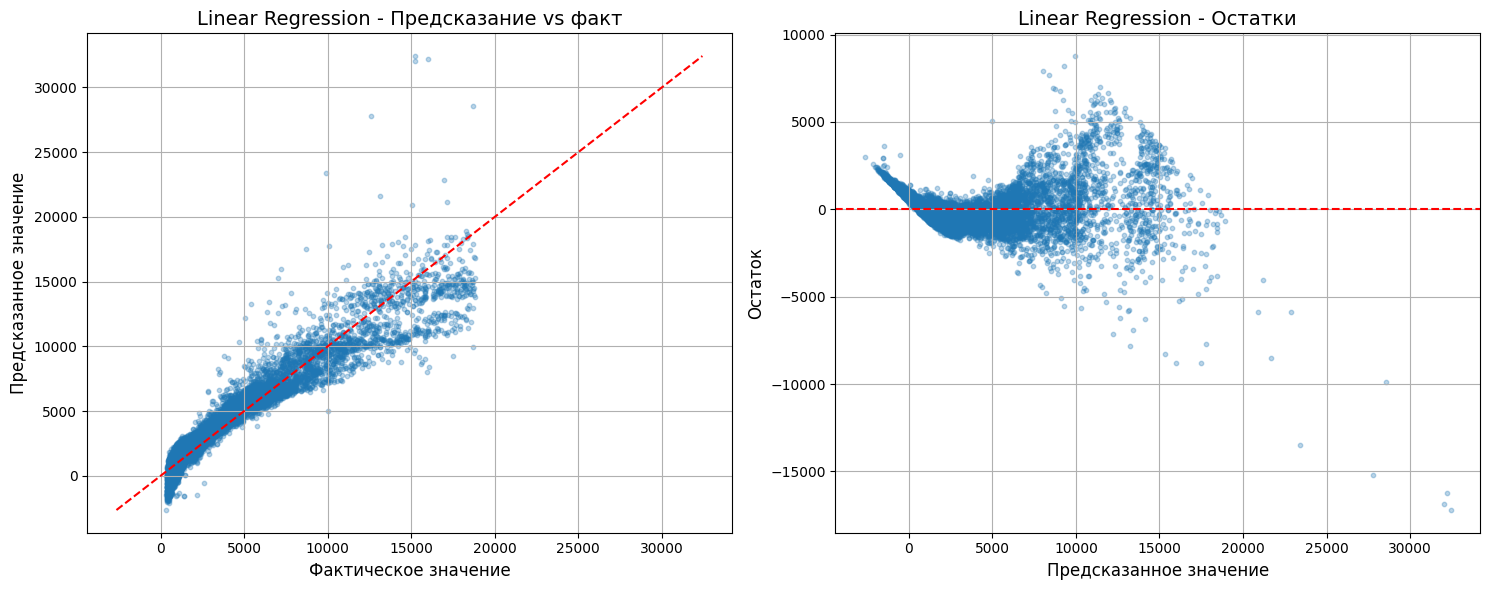


                LINEAR REGRESSION EVALUATION                

MAIN METRICS:
 Metric     Value
    MAE  805.2744
   RMSE 1224.5965
     R2    0.9057
MAPE, %   44.5678



In [48]:
lin_reg = LinearRegression()
lin_reg.fit(X_train_preprocessed, y_train)
y_pred = lin_reg.predict(X_test_preprocessed)

lin_reg_metrics = evaluate_regression(
    y_test=y_test, y_pred=y_pred, model_name="Linear Regression"
)

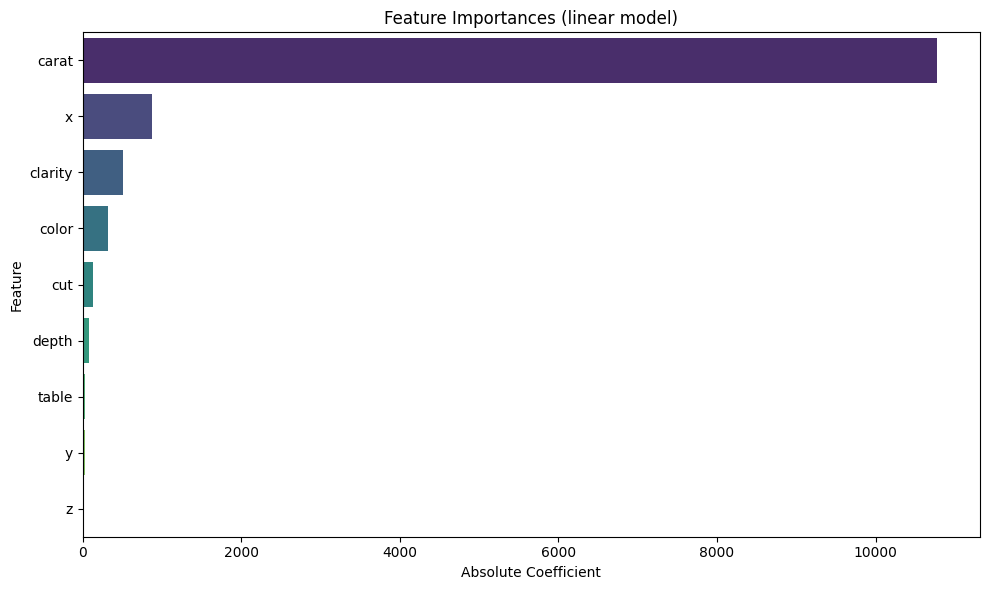

,Feature,Importance
3,carat,10778.015766
6,x,873.291561
2,clarity,502.521117
1,color,323.871749
0,cut,123.861123
4,depth,81.084843
5,table,27.078427
7,y,22.896718
8,z,15.706576


In [49]:
# Построим гистограмму важностей для каждой фичи
plot_feature_importance(lin_reg, feature_names)

В случае линейной регрессии на первом месте оказался carat

### 6.3 Дерево решений

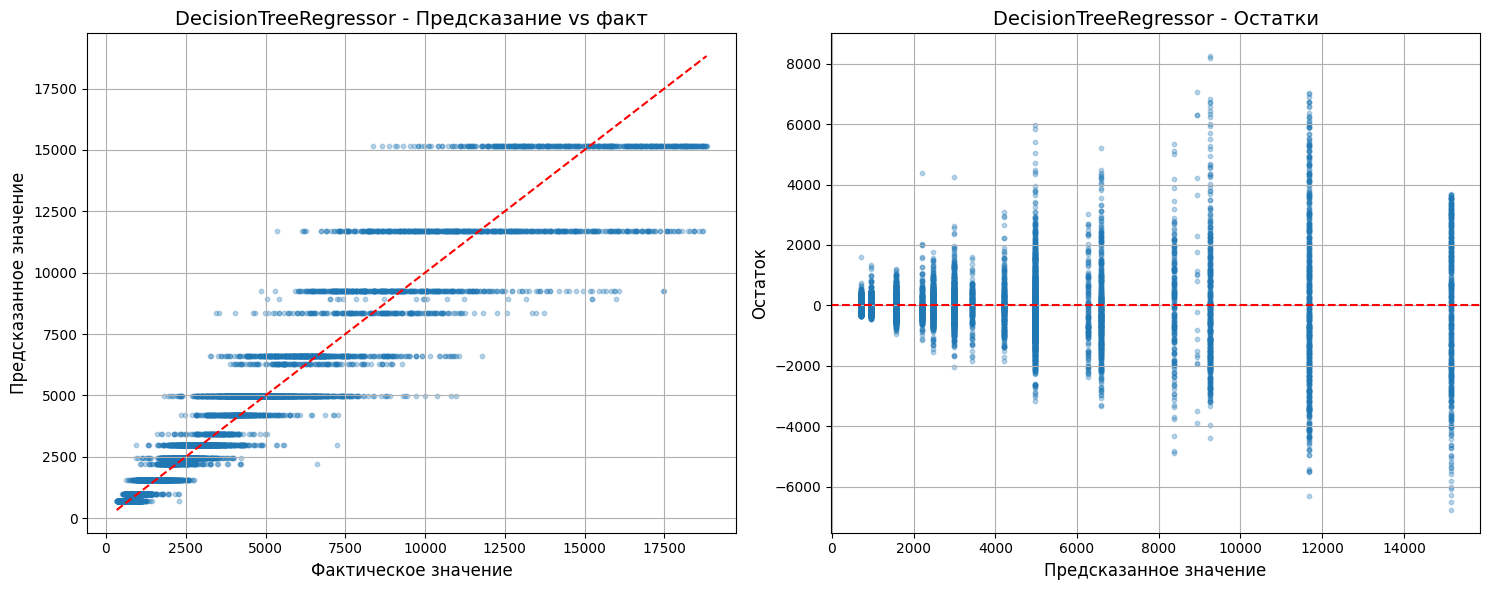


              DECISIONTREEREGRESSOR EVALUATION              

MAIN METRICS:
 Metric     Value
    MAE  668.7587
   RMSE 1161.5802
     R2    0.9151
MAPE, %   19.2621



In [54]:
decision_tree = DecisionTreeRegressor(random_state=SEED, max_depth=4)
decision_tree.fit(X_train_preprocessed, y_train)
y_pred = decision_tree.predict(X_test_preprocessed)

decision_tree_metrics = evaluate_regression(
    y_test=y_test, y_pred=y_pred, model_name="DecisionTreeRegressor"
)


Даже неглубокое дерево (max_depth=4) превосходит линейную модель по MAE и особенно по MAPE (≈ 19%). Это значит есть нелинейные зависимости в данных

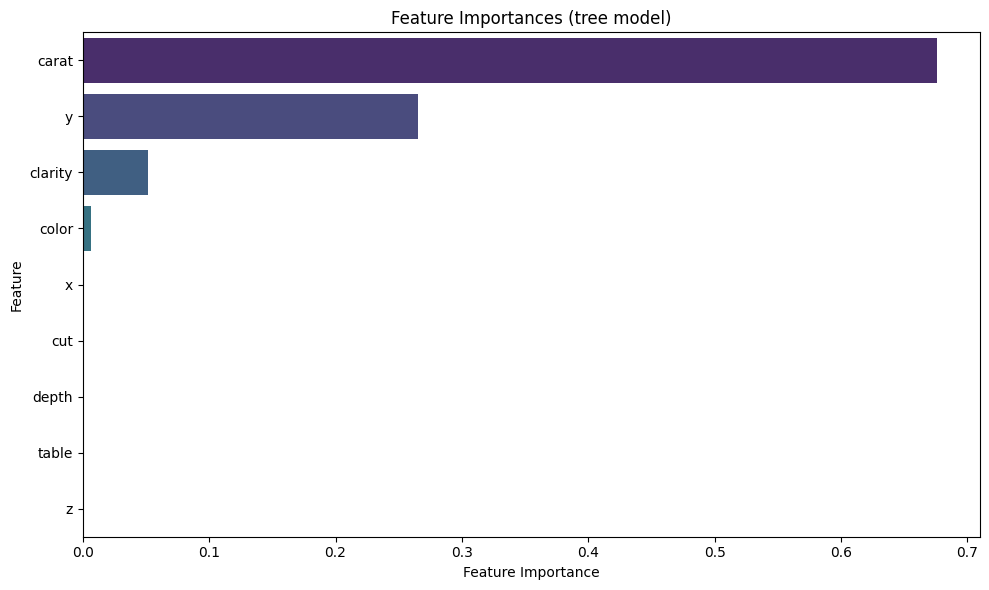

,Feature,Importance
3,carat,0.676208
7,y,0.265552
2,clarity,0.051378
1,color,0.006516
6,x,0.000346
0,cut,0.000000
4,depth,0.000000
5,table,0.000000
8,z,0.000000


In [51]:
plot_feature_importance(decision_tree, feature_names)

Модель опирается почти исключительно в основном на carat и y

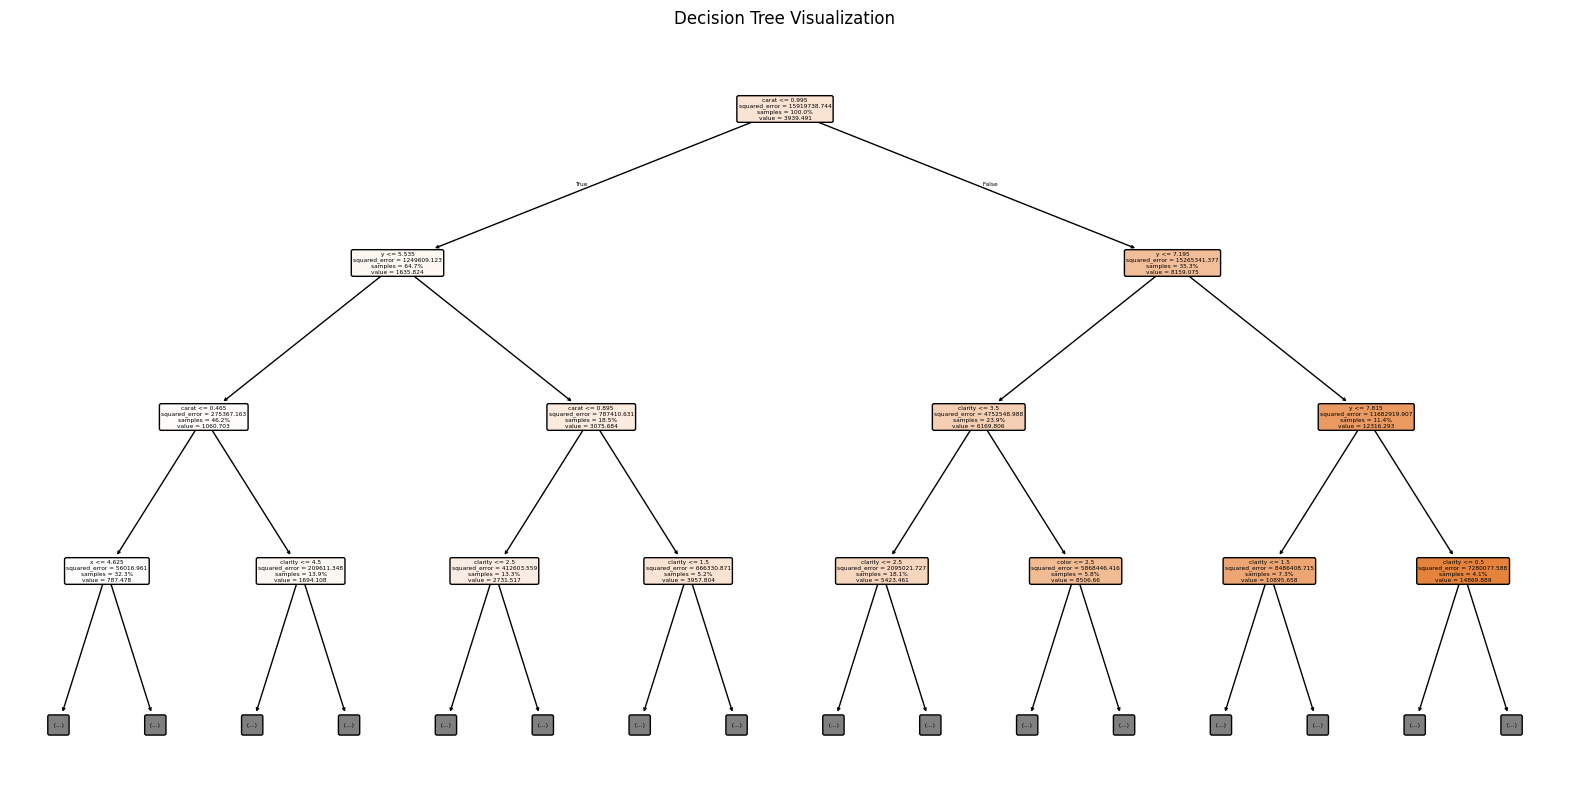

In [53]:
# Визуализируем наше дерево решений
visualize_decision_tree(decision_tree, feature_names, max_depth=3)


### 6.4 Случайный лес

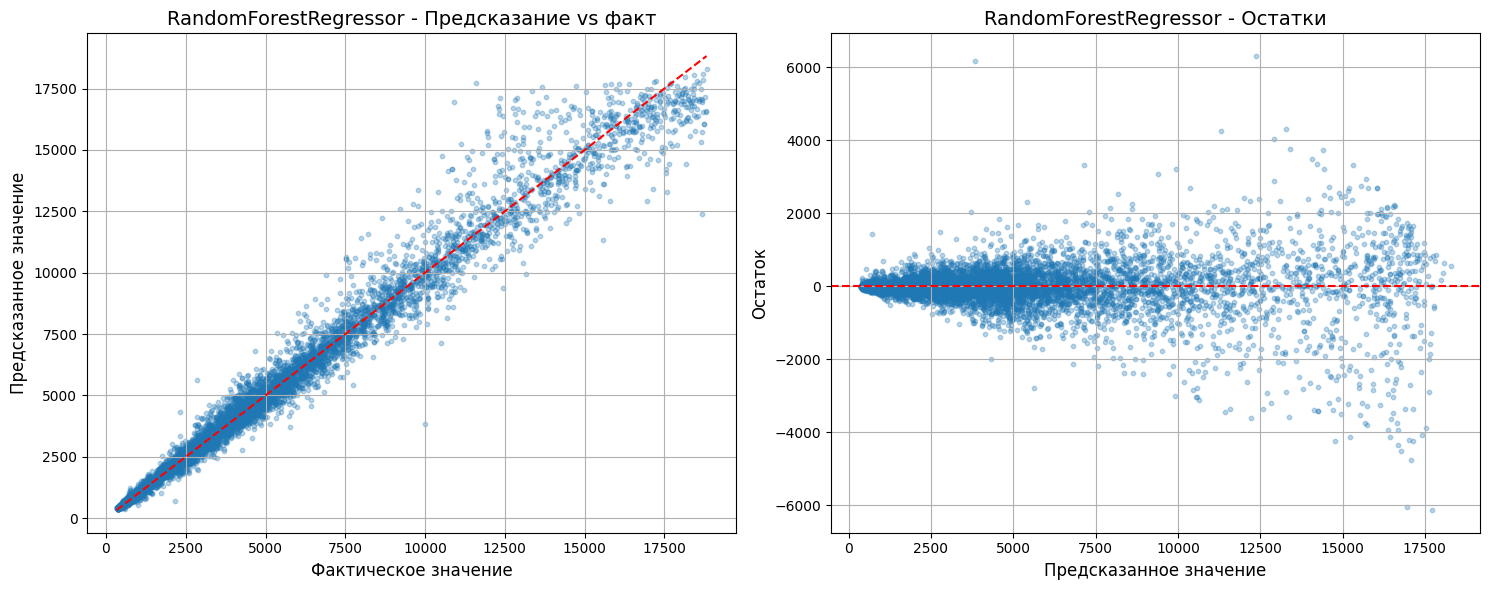


              RANDOMFORESTREGRESSOR EVALUATION              

MAIN METRICS:
 Metric    Value
    MAE 266.5924
   RMSE 540.9979
     R2   0.9816
MAPE, %   6.3523



In [57]:
random_forest = RandomForestRegressor(random_state=SEED, n_jobs=-1)
random_forest.fit(X_train_preprocessed, y_train)
y_pred = random_forest.predict(X_test_preprocessed)

random_forest_metrics = evaluate_regression(
    y_test=y_test, y_pred=y_pred, model_name="RandomForestRegressor"
)


Ошибка резко упала, значит ансамбль глубоких деревьев намного точнее одиночного дерева

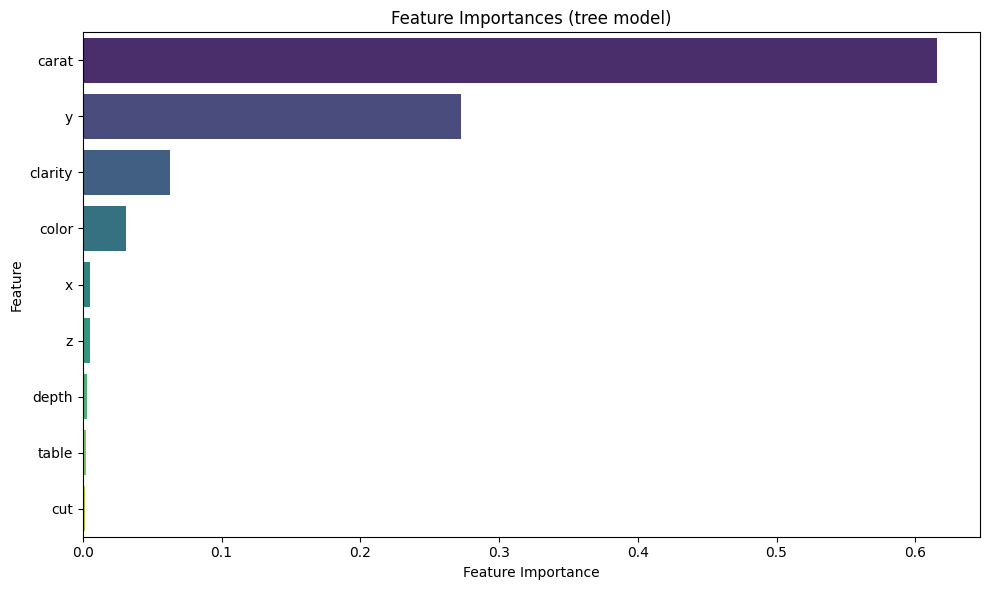

,Feature,Importance
3,carat,0.615866
7,y,0.272544
2,clarity,0.062980
1,color,0.031078
6,x,0.005177
8,z,0.005086
4,depth,0.003159
5,table,0.002282
0,cut,0.001827


In [58]:
plot_feature_importance(random_forest, feature_names)

### 6.5 Градиентный бустинг

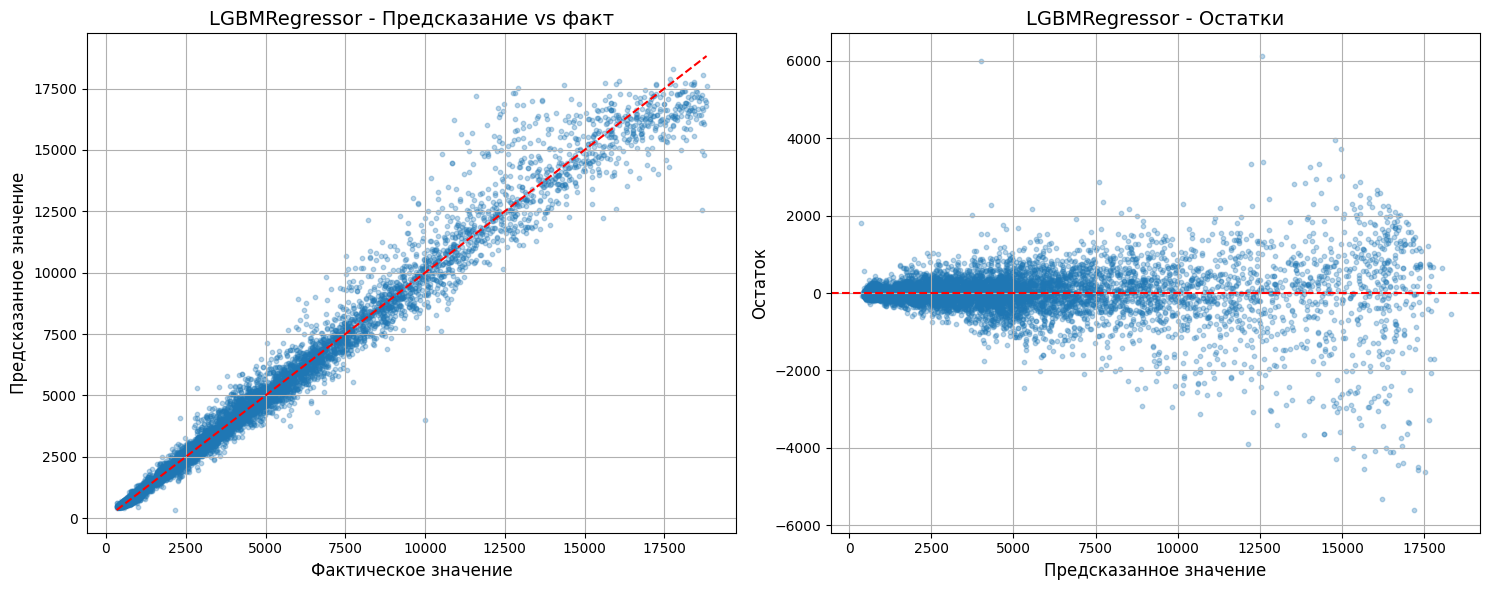


                  LGBMREGRESSOR EVALUATION                  

MAIN METRICS:
 Metric    Value
    MAE 276.4565
   RMSE 530.8922
     R2   0.9823
MAPE, %   8.0581



In [59]:
lgbm = LGBMRegressor(random_state=SEED, verbose=-1)
lgbm.fit(X_train_preprocessed, y_train)
y_pred = lgbm.predict(X_test_preprocessed)

lgbm_metrics = evaluate_regression(
    y_test=y_test, y_pred=y_pred, model_name="LGBMRegressor"
)

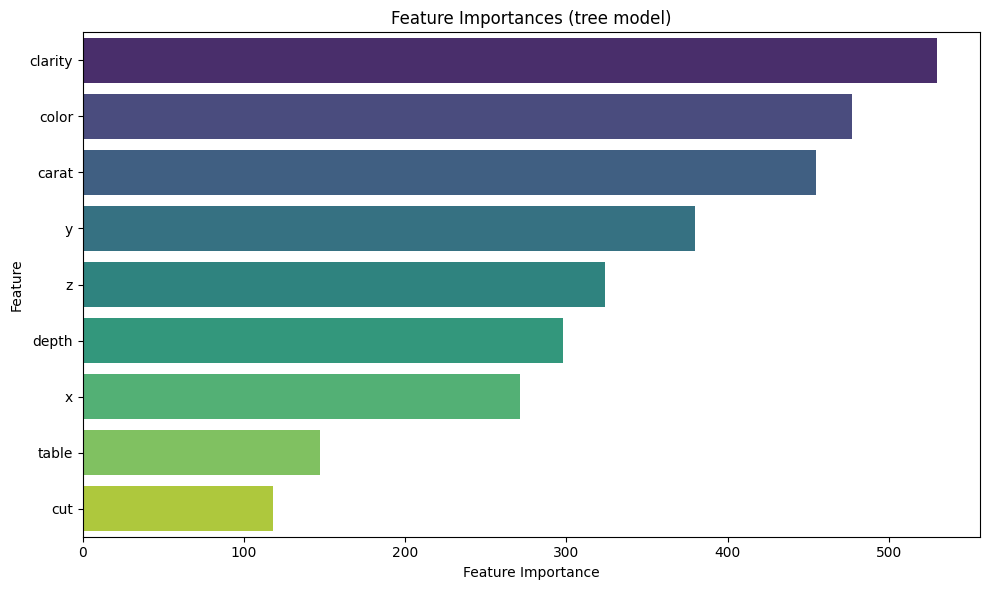

,Feature,Importance
2,clarity,530
1,color,477
3,carat,455
7,y,380
8,z,324
4,depth,298
6,x,271
5,table,147
0,cut,118


In [60]:
plot_feature_importance(lgbm, feature_names)

### 6.6 Финальное сравнение метрик

In [61]:
final_metrics = {
    'dummy_regressor': dummy_regressor_metrics,
    'lin_reg': lin_reg_metrics,
    'decision_tree': decision_tree_metrics,
    'random_forest': random_forest_metrics,
    'lgbm': lgbm_metrics
}

result = pd.DataFrame(final_metrics.values(), index=final_metrics.keys())

In [62]:
result

,MAE,RMSE,R2,"MAPE, %"
dummy_regressor,3020.505839,3987.222176,-0.000070,190.168223
lin_reg,805.274366,1224.596542,0.905664,44.567800
decision_tree,668.758717,1161.580222,0.915123,19.262068
random_forest,266.592430,540.997942,0.981589,6.352346
lgbm,276.456459,530.892193,0.982270,8.058122


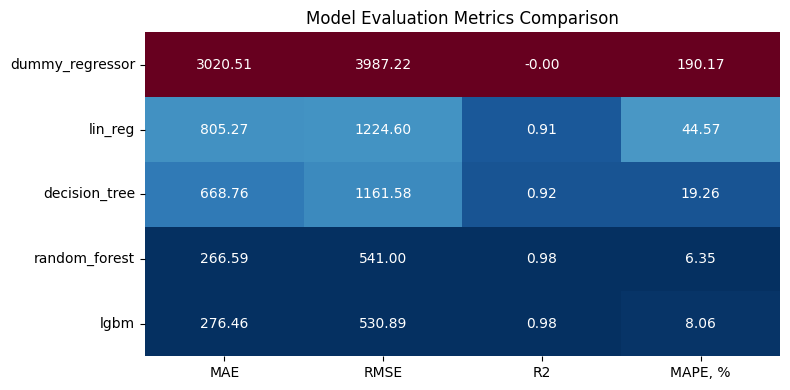

In [63]:
plot_regression_metrics_heatmap(result)